*Mathematical Foundations of Robotics · Chapter 5 — Velocity Kinematics, Jacobians, Singularities and Statics*

# 5.2 The Manipulator Jacobian

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/05-velocity-kinematics-and-statics/5.2-the-manipulator-jacobian.ipynb)


The **Jacobian** is the matrix that turns joint rates into the velocity of the tool, $\dot{\mathbf x}=J(\mathbf q)\dot{\mathbf q}$. It is
the most useful single object in manipulator kinematics: its inverse drives the tool along a path, its transpose maps forces to joint torques
(Notebook 5.5), and its rank tells where the arm loses a degree of freedom (Notebook 5.4). This notebook builds $J$ in three equivalent
ways — by differentiating the forward kinematics, by the geometric column construction, and by running Craig's velocity propagation once per
joint — compares them on planar and spatial examples, and then checks the same matrix against MuJoCo's own Jacobian for a real UR5e, a
Franka Panda and a Dynamixel two-link arm.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., Ch. 5, §5.6 (Jacobians), with §5.5 (velocity propagation) as the second route to the same matrix |
| **Parallel reading** | Lynch & Park §5.1 (space and body Jacobians) · Siciliano et al. Ch. 3 (geometric Jacobian, Jacobian computation) · Spong et al., the chapter on the manipulator Jacobian · Corke *RVC* Ch. 8 |
| **Lectures** | [ThatsEngineering — Jacobian matrix and singularities (part 1)](https://www.youtube.com/watch?v=h2YM0CDzDl4) · [ThatsEngineering — Jacobian by partial differentiation (part 2)](https://www.youtube.com/watch?v=YS3kt_eqOPY) · [Modern Robotics — 5.1.1 Space Jacobian](https://www.youtube.com/watch?v=KbI8HN3imtQ) · [Modern Robotics — 5.1.2 Body Jacobian](https://www.youtube.com/watch?v=69HeL2XvL9Y) |
| **Prerequisites** | [5.1 Velocity of Rigid Bodies and Velocity Propagation](5.1-velocity-of-rigid-bodies-and-propagation.ipynb) |
| **Study time** | about 3 hours |

## Learning objectives

1. Define the Jacobian as the configuration-dependent linear map from joint rates to tool velocity, and state its dimensions.
2. Derive the Jacobian of a planar arm by differentiating the forward kinematics.
3. Construct the columns of the geometric Jacobian for revolute and prismatic joints, $\big[\hat z_i\times(\mathbf p_n-\mathbf p_i);\ \hat z_i\big]$ and $[\hat z_i;\ \mathbf 0]$, and explain why the construction is valid.
4. Obtain the Jacobian from velocity propagation by setting one joint rate to unity at a time.
5. Use $J$ and $J^{-1}$ for resolved-rate motion, and recognise the drift of open-loop Euler integration.
6. Verify a hand-built Jacobian of a real robot against the simulator, paying attention to the frame in which MuJoCo expresses it.

## Contents

1. [The Jacobian as a linear map](#1.-The-Jacobian-as-a-linear-map)
2. [Method A: differentiating the forward kinematics](#2.-Method-A:-differentiating-the-forward-kinematics)
3. [Method B: the geometric column construction](#3.-Method-B:-the-geometric-column-construction)
4. [Method C: from velocity propagation](#4.-Method-C:-from-velocity-propagation)
5. [Spatial and prismatic examples](#5.-Spatial-and-prismatic-examples)
6. [Using the Jacobian: resolved-rate motion](#6.-Using-the-Jacobian:-resolved-rate-motion)
7. [Real robots: UR5e, Panda and a Dynamixel two-link arm](#7.-Real-robots:-UR5e,-Panda-and-a-Dynamixel-two-link-arm)
8. [Worked examples](#8.-Worked-examples)
9. [Summary, common mistakes and exercises](#9.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit.transforms import rotx, roty, rotz, make_T, inv_T, skew, unskew, transl
from rgkit.kinematics import fk_dh, fk_tool, planar_fk
from rgkit import jacobian as jc
import sympy as sp

## 1. The Jacobian as a linear map

A manipulator with $n$ joints has joint variables $\mathbf q\in\mathbb R^n$ and a tool pose described by $m$ task coordinates
$\mathbf x=f(\mathbf q)$. The chain rule gives the velocity of the task coordinates,

$$
\dot{\mathbf x}=\frac{\partial f}{\partial\mathbf q}\,\dot{\mathbf q}=J(\mathbf q)\,\dot{\mathbf q},\qquad
J_{ij}=\frac{\partial f_i}{\partial q_j}\in\mathbb R^{m\times n}.
$$

At a fixed configuration this is an ordinary matrix–vector product, so **tool velocity is a linear function of joint rate**; as
the arm moves the matrix itself changes, which is why one writes $J(\mathbf q)$. Row $i$ belongs to a task coordinate and
column $j$ to a joint. Column $j$ has a simple meaning: it is **the tool velocity produced by joint $j$ alone moving at unit rate**.

For a spatial arm the usual task velocity is the six-vector $[\mathbf v;\ \boldsymbol\omega]$ of linear and angular velocity (Notebook 5.1),
and $J$ is $6\times n$; for a planar arm following a point it is $2\times n$. Because there is no three-parameter function whose time
derivative is $\boldsymbol\omega$ (Notebook 5.3), the six-row matrix is called the **geometric Jacobian**. If $m=n$ the matrix is square, and where it is
invertible, $\dot{\mathbf q}=J^{-1}\dot{\mathbf x}$ answers the inverse question: *which joint rates produce the tool velocity I want?*

## 2. Method A: differentiating the forward kinematics

For the planar two-link arm of lengths $L_1,L_2$ the tool position is
$x=L_1c_1+L_2c_{12}$, $y=L_1s_1+L_2s_{12}$, where $c_{12}=\cos(\theta_1+\theta_2)$ and so on. Differentiating in time with
$\tfrac{d}{dt}c_{12}=-s_{12}(\dot\theta_1+\dot\theta_2)$,

$$
\begin{bmatrix}\dot x\\ \dot y\end{bmatrix}=
\underbrace{\begin{bmatrix}-L_1s_1-L_2s_{12} & -L_2s_{12}\\ \phantom{-}L_1c_1+L_2c_{12} & \phantom{-}L_2c_{12}\end{bmatrix}}_{J(\boldsymbol\theta)}
\begin{bmatrix}\dot\theta_1\\ \dot\theta_2\end{bmatrix}.
$$

Reading the columns geometrically: the second is $L_2(-s_{12},c_{12})$, the velocity the tip gets when only the elbow turns — perpendicular to link
2 with magnitude $L_2$; the first is perpendicular to the line from the shoulder to the tip, with magnitude equal to the length of that line. The determinant is
$\det J=L_1L_2(c_1s_{12}-s_1c_{12})=L_1L_2\sin\theta_2$, a result with a profound consequence (Notebook 5.4).

Method A is the right tool when a closed form for $f$ exists and the arm is simple. A computer algebra system removes the labour: below, `sympy`
differentiates the position of the planar **three-link** arm, and appends a row for the tool orientation $\phi=\theta_1+\theta_2+\theta_3$ (for a
planar arm the orientation *is* a scalar function of $\mathbf q$ whose derivative is the angular velocity).

In [2]:
th = sp.symbols("theta1:4", real=True); L = sp.symbols("L1:4", positive=True)
phi = [sum(th[:k + 1]) for k in range(3)]
x = sum(L[k] * sp.cos(phi[k]) for k in range(3))
y = sum(L[k] * sp.sin(phi[k]) for k in range(3))
f = sp.Matrix([x, y, phi[2]])
J_sym = f.jacobian(th)
display(Math(r"J(\boldsymbol\theta)=" + sp.latex(sp.simplify(J_sym))))
display(Math(r"\det J = " + sp.latex(sp.simplify(J_sym.det()))))

# numerical value, compared with the library routine
Lval = [1.0, 0.8, 0.5]; qval = np.array([deg(30), deg(-20), deg(50)])
J_num = np.array(J_sym.subs(dict(zip(L, Lval)) | dict(zip(th, qval))), dtype=float)
print("symbolic = library planar_jacobian:", np.allclose(J_num, jc.planar_jacobian(Lval, qval, orientation=True)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

symbolic = library planar_jacobian: True


The determinant of the $3\times3$ planar Jacobian (position plus orientation) involves only $L_1L_2\sin\theta_2$: the
wrist point is moved only by the first two joints, and the third merely orients the tool.

**Limits of Method A.** It differentiates *position*. For orientation in space no function $g(\mathbf q)$ exists whose derivative
is $\boldsymbol\omega$, so one either differentiates a chosen three-angle representation (the *analytical* Jacobian, Notebook 5.3) or
uses the constructions below, which deliver $\boldsymbol\omega$ directly and work for every serial chain.

## 3. Method B: the geometric column construction

Fix all joints but the $i$-th and let it move at the rate $\dot q_i$. Links $i,i+1,\dots,n$ and the tool then form **one rigid body**
that rotates (revolute joint) about the axis through a point $\mathbf p_i$ with direction $\hat{\mathbf z}_i$, or translates (prismatic joint) along $\hat{\mathbf z}_i$.
By the rigid-body formula of Notebook 5.1 the tool, at $\mathbf p_n$, acquires

$$
\text{revolute:}\quad \mathbf v=\dot q_i\,\hat{\mathbf z}_i\times(\mathbf p_n-\mathbf p_i),\ \ \boldsymbol\omega=\dot q_i\hat{\mathbf z}_i;
\qquad
\text{prismatic:}\quad \mathbf v=\dot q_i\hat{\mathbf z}_i,\ \ \boldsymbol\omega=\mathbf 0.
$$

Velocities of the same body add (the angular velocities add as vectors, and the linear velocities of a *single* point add because $\mathbf v=\mathbf v_O+\boldsymbol\omega\times\mathbf r$
is linear in the twist), so the contributions of all joints may be summed. Reading off the coefficient of each $\dot q_i$:

> **Geometric Jacobian, base-frame form.**
> $$ {}^{0}J=\big[\mathbf j_1\ \cdots\ \mathbf j_n\big],\qquad
> \mathbf j_i=\begin{cases}\begin{bmatrix}\hat{\mathbf z}_i\times(\mathbf p_n-\mathbf p_i)\\ \hat{\mathbf z}_i\end{bmatrix} & \text{revolute},\\[2ex]
> \begin{bmatrix}\hat{\mathbf z}_i\\ \mathbf 0\end{bmatrix} & \text{prismatic},\end{cases}$$
> with $\hat{\mathbf z}_i={}^{0}_{i}R\,[0\ 0\ 1]^{\mathsf T}$ and $\mathbf p_i={}^{0}P_{iORG}$ read from the cumulative transforms ${}^{0}_{i}T$ of the
> *modified* D-H table, and $\mathbf p_n$ the origin of the tool frame. (In the *standard* convention the axis of joint $i$ is $\hat z_{i-1}$.)

Every ingredient is available from forward kinematics, and **no differentiation is needed**. Notice the frame in which the result is expressed:
everything is described in the base frame $\{0\}$ and refers to the velocity of the point $\mathbf p_n$. Both choices can be changed (Notebook 5.3).

The function below is a transparent version of what `rgkit.jacobian.jacobian_geometric` does. It is compared with the sympy result of Section 2 (a planar arm, where all axes are
$\hat z$ and $\mathbf p_i$ are the joint positions), and with differentiation by finite differences for a spatial chain.

In [3]:
def my_jacobian(table, q, tool=None):
    """Geometric Jacobian in the base frame, written out column by column (modified D-H)."""
    Ts = fk_dh(table, q)
    T_tool = Ts[-1] if tool is None else Ts[-1] @ tool
    p_n = T_tool[:3, 3]
    cols = []
    for i, row in enumerate(table, start=1):
        z_i, p_i = Ts[i][:3, 2], Ts[i][:3, 3]
        if row[4] == "R":
            cols.append(np.r_[np.cross(z_i, p_n - p_i), z_i])
        else:
            cols.append(np.r_[z_i, np.zeros(3)])
    return np.array(cols).T

# planar three-link arm as a D-H chain (the last row is the fixed tip frame)
tab3 = [(0, 0, 0, 0, "R"), (0, Lval[0], 0, 0, "R"), (0, Lval[1], 0, 0, "R"), (0, Lval[2], 0, 0, "R")]
Jb = my_jacobian(tab3, np.r_[qval, 0.0])[:, :3]
print("6 x 3 geometric Jacobian of the planar 3R arm (rows: vx vy vz wx wy wz):\n", Jb)
print("rows vx, vy, wz equal the sympy J:", np.allclose(Jb[[0, 1, 5]], J_num))

# a spatial chain: compare with differentiation of the forward kinematics (finite differences)
rng = np.random.default_rng(3)
tab = [(rng.uniform(-3, 3), rng.uniform(-.4, .4), rng.uniform(-.4, .4), rng.uniform(-3, 3), k) for k in "RRRPRR"]
q_ = rng.uniform(-1, 1, 6)
J_fd = jc.jacobian_numeric(lambda x: fk_tool(tab, x), q_)
print("spatial 6R/P chain: column construction = finite differences:", np.allclose(my_jacobian(tab, q_), J_fd, atol=1e-6),
      "  library routine:", np.allclose(jc.jacobian_geometric(tab, q_), J_fd, atol=1e-6))

6 x 3 geometric Jacobian of the planar 3R arm (rows: vx vy vz wx wy wz):
 [[-1.0719 -0.5719 -0.433 ]
 [ 1.9039  1.0378  0.25  ]
 [ 0.      0.      0.    ]
 [ 0.      0.      0.    ]
 [ 0.      0.      0.    ]
 [ 1.      1.      1.    ]]
rows vx, vy, wz equal the sympy J: True
spatial 6R/P chain: column construction = finite differences: True   library routine: True


**Seeing the columns.** For the planar two-link arm the two columns of $J$ are the tip velocities that each joint would produce alone; the actual tip velocity is their
sum $\dot\theta_1\mathbf j_1+\dot\theta_2\mathbf j_2$, weighted by the joint rates. The animation draws both contributions
and their sum while the arm follows a prescribed joint motion. Column $\mathbf j_1$ is perpendicular to the shoulder-to-tip line, column $\mathbf j_2$ perpendicular to the forearm.

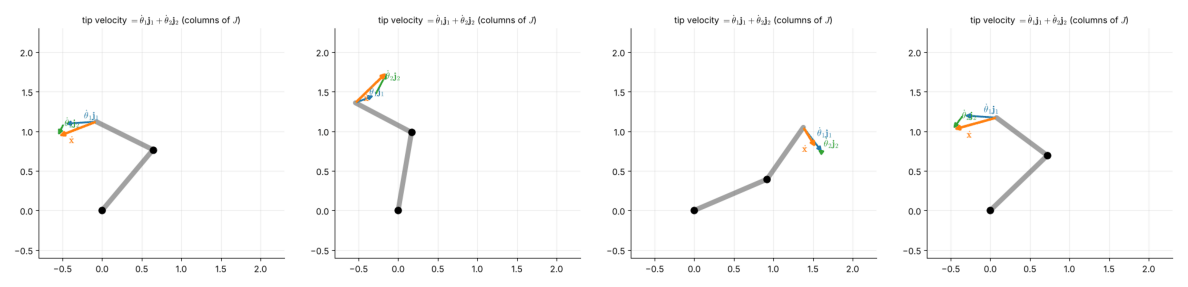

In [4]:
L1, L2 = 1.0, 0.8
fig, ax = plt.subplots(figsize=(5.6, 5.0))

def update(s):
    t = 2 * np.pi * s
    q = np.array([deg(50) + deg(35) * np.sin(t), deg(70) + deg(40) * np.sin(t + 1.0)])
    qd = np.array([deg(35) * np.cos(t), deg(40) * np.cos(t + 1.0)])
    pts = planar_fk([L1, L2], q)
    J = jc.planar_jacobian([L1, L2], q)
    c1, c2 = J[:, 0] * qd[0], J[:, 1] * qd[1]
    ax.cla()
    ax.plot(pts[:, 0], pts[:, 1], "-", color="#555", lw=6, solid_capstyle="round", alpha=0.55)
    ax.plot(pts[:2, 0], pts[:2, 1], "ko", ms=8)
    tip = pts[2]
    k = 0.6                                                         # display scale for velocities
    ax.annotate("", xy=tip + k * c1, xytext=tip, arrowprops=dict(arrowstyle="-|>", color="#1f77b4", lw=2.2))
    ax.annotate("", xy=tip + k * c1 + k * c2, xytext=tip + k * c1, arrowprops=dict(arrowstyle="-|>", color="#2ca02c", lw=2.2))
    ax.annotate("", xy=tip + k * (c1 + c2), xytext=tip, arrowprops=dict(arrowstyle="-|>", color="#ff7f0e", lw=3))
    ax.text(*(tip + k * c1 / 2 + 0.05), r"$\dot\theta_1\mathbf{j}_1$", color="#1f77b4", fontsize=11)
    ax.text(*(tip + k * c1 + k * c2 / 2 + 0.05), r"$\dot\theta_2\mathbf{j}_2$", color="#2ca02c", fontsize=11)
    ax.text(*(tip + k * (c1 + c2) / 2 - np.array([0.1, 0.18])), r"$\dot{\mathbf{x}}$", color="#ff7f0e", fontsize=12)
    ax.set_xlim(-0.8, 2.3); ax.set_ylim(-0.6, 2.3); ax.set_aspect("equal"); ax.grid(alpha=0.25)
    ax.set_title(r"tip velocity $=\dot\theta_1\mathbf{j}_1+\dot\theta_2\mathbf{j}_2$ (columns of $J$)", fontsize=10.5)

animate(fig, update, np.linspace(0, 1, 36, endpoint=False), interval=100, gif="assets/5.2-jacobian-columns-2R.gif", n_keyframes=4)

## 4. Method C: from velocity propagation

Craig's route (§5.6) uses the outward iteration of Notebook 5.1. Because the tool velocity is linear in the joint rates, one can
choose $\dot{\mathbf q}=\mathbf e_j$ (a one in position $j$, zeros elsewhere) and propagate; the resulting
$[{}^{n}\mathbf v_n;\ {}^{n}\boldsymbol\omega_n]$ **is** column $j$. Doing this for $j=1,\dots,n$ produces the Jacobian written in the **last link's frame**, ${}^{n}J$.
Hand calculation is easiest here, because every vector is a short expression in the link frames — this is how Craig derives his Jacobians.
The base-frame matrix follows by a change of frame (Notebook 5.3),
${}^{0}J=\operatorname{diag}({}^{0}_{n}R,\ {}^{0}_{n}R)\,{}^{n}J$. In code, `jacobian_by_propagation` does exactly this.

In [5]:
nJ = jc.jacobian_by_propagation(tab, q_)                       # Jacobian in the frame of the last link
R_0n = fk_dh(tab, q_)[-1][:3, :3]
J0_from_prop = jc.jacobian_in_frame(nJ, R_0n)                  # rotate both blocks into the base frame
print("propagation (rotated to base) = column construction:", np.allclose(J0_from_prop, my_jacobian(tab, q_)))
print("column 4 is prismatic: its angular part is zero in every method:", np.allclose(nJ[3:, 3], 0))

propagation (rotated to base) = column construction: True
column 4 is prismatic: its angular part is zero in every method: True


| | Differentiate $f(\mathbf q)$ | Geometric columns | Propagation |
|:--|:--|:--|:--|
| Needs | closed-form position | axes $\hat{\mathbf z}_i$ and points $\mathbf p_i$ from FK | the link transforms, one pass per joint |
| Gives | position rows (orientation only via an angle set) | full $6\times n$ in the base frame | full $6\times n$ in the last frame |
| Best for | planar arms, symbolic work | numerical code for any chain | hand derivation, Craig's examples |

All three give identical matrices (up to the choice of frame). Numerical libraries almost always use the column construction, because it needs nothing but the
joint axes and positions.

## 5. Spatial and prismatic examples

**A spherical-coordinate arm (R–R–P).** A vertical pan joint $q_1$, a horizontal elevation joint $q_2$ and a telescoping prismatic link $q_3$ carry the tool a distance $q_3$
from the pivot at height $h$. In modified D-H form the rows are $(0,0,h,\theta_1)$, $(90^\circ,0,0,\theta_2+90^\circ)$ and $(90^\circ,0,0,0;\ P)$ (the offset $90^\circ$ in row 2 makes $q_2=0$ the horizontal
direction). The tool position is the spherical-coordinate expression

$$
\mathbf p=\big(q_3\cos q_2\cos q_1,\ \ q_3\cos q_2\sin q_1,\ \ h+q_3\sin q_2\big).
$$

We verify this, derive the Jacobian of $\mathbf p$ with sympy (Method A), and compare with the geometric construction (Method B), including the **prismatic column**: it has no
angular part, and its linear part is simply the direction of the slide, the unit vector along the arm.

In [6]:
h = 0.4
rrp = [(0, 0, h, 0, "R"), (np.pi / 2, 0, 0, np.pi / 2, "R"), (np.pi / 2, 0, 0, 0, "P")]
q1s, q2s, q3s = sp.symbols("q1 q2 q3", real=True)
p_sym = sp.Matrix([q3s * sp.cos(q2s) * sp.cos(q1s), q3s * sp.cos(q2s) * sp.sin(q1s), h + q3s * sp.sin(q2s)])
display(Math(r"J_v=\partial\mathbf p/\partial\mathbf q=" + sp.latex(sp.simplify(p_sym.jacobian([q1s, q2s, q3s])))))

qv = np.array([deg(35), deg(25), 0.7])
Tv = fk_dh(rrp, qv)[-1]
p_formula = np.array(p_sym.subs({q1s: qv[0], q2s: qv[1], q3s: qv[2]}), dtype=float).ravel()
print("D-H position = spherical-coordinate formula:", np.allclose(Tv[:3, 3], p_formula))
J_rrp = jc.jacobian_geometric(rrp, qv)
Jv_sym = np.array(p_sym.jacobian([q1s, q2s, q3s]).subs({q1s: qv[0], q2s: qv[1], q3s: qv[2]}), dtype=float)
print("geometric J (linear rows) = sympy derivative:", np.allclose(J_rrp[:3], Jv_sym))
print("prismatic column:", J_rrp[:, 2].round(4), " = unit vector along the arm:", np.allclose(J_rrp[:3, 2], (Tv[:3, 3] - np.array([0, 0, h])) / qv[2]))
print("rows 4-6 of J (angular velocity):\n", J_rrp[3:].round(4))

<IPython.core.display.Math object>

D-H position = spherical-coordinate formula: True
geometric J (linear rows) = sympy derivative: True
prismatic column: [0.7424 0.5198 0.4226 0.     0.     0.    ]  = unit vector along the arm: True
rows 4-6 of J (angular velocity):
 [[ 0.      0.5736  0.    ]
 [ 0.     -0.8192  0.    ]
 [ 1.      0.      0.    ]]


**A SCARA arm (R–R–P–R).** The four-joint arm of Selective-Compliance type moves a tool in $x,y,z$ and spins it about the vertical. Its prismatic axis points *down*
($\alpha_2=180^\circ$ in the table below), so its column is $[0,0,-1,0,0,0]^{\mathsf T}$; its last revolute axis also points down, so the last column is $[\mathbf 0;\,-\hat z]$ (and the linear part is zero because the tool
point lies on that axis). Only four of the six rows are independent, and the Jacobian has rank four: **a four-joint arm can reach only a four-dimensional set of velocities**.

In [7]:
Ls1, Ls2 = 0.5, 0.4
scara = [(0, 0, 0, 0, "R"), (0, Ls1, 0, 0, "R"), (np.pi, Ls2, 0, 0, "P"), (0, 0, 0, 0, "R")]
qs = np.array([deg(30), deg(60), 0.15, deg(20)])
Js = jc.jacobian_geometric(scara, qs)
print(Js.round(4))
print("rank =", np.linalg.matrix_rank(Js), " | numerical check:", np.allclose(Js, jc.jacobian_numeric(lambda x: fk_dh(scara, x)[-1], qs), atol=1e-6))
s1, s12, c1, c12 = np.sin(qs[0]), np.sin(qs[0] + qs[1]), np.cos(qs[0]), np.cos(qs[0] + qs[1])
print("first column (-L1 s1 - L2 s12, L1 c1 + L2 c12):", np.round([-Ls1 * s1 - Ls2 * s12, Ls1 * c1 + Ls2 * c12], 4))

[[-0.65  -0.4    0.     0.   ]
 [ 0.433  0.    -0.    -0.   ]
 [ 0.     0.    -1.     0.   ]
 [ 0.     0.     0.     0.   ]
 [ 0.     0.     0.    -0.   ]
 [ 1.     1.     0.    -1.   ]]
rank = 4  | numerical check: True
first column (-L1 s1 - L2 s12, L1 c1 + L2 c12): [-0.65   0.433]


## 6. Using the Jacobian: resolved-rate motion

If $J$ is square and invertible the joint rates for a desired tool velocity are $\dot{\mathbf q}=J^{-1}(\mathbf q)\,\dot{\mathbf x}_d$ — **resolved-rate
motion** (the term is due to Whitney). To follow a path, one integrates
$\mathbf q_{k+1}=\mathbf q_k+\Delta t\,J^{-1}(\mathbf q_k)\,\dot{\mathbf x}_d$. Because the Jacobian is only a *first-order* model of the motion
over one time step, plain Euler integration accumulates error. Adding a **feedback term** that
corrects the measured position error, $\dot{\mathbf q}=J^{-1}\big(\dot{\mathbf x}_d+K(\mathbf x_d-\mathbf x)\big)$, removes the drift. The figure
compares both on a straight-line path of the two-link arm ($L_1=1$, $L_2=0.8$) travelled at constant speed in $T=2$ s.

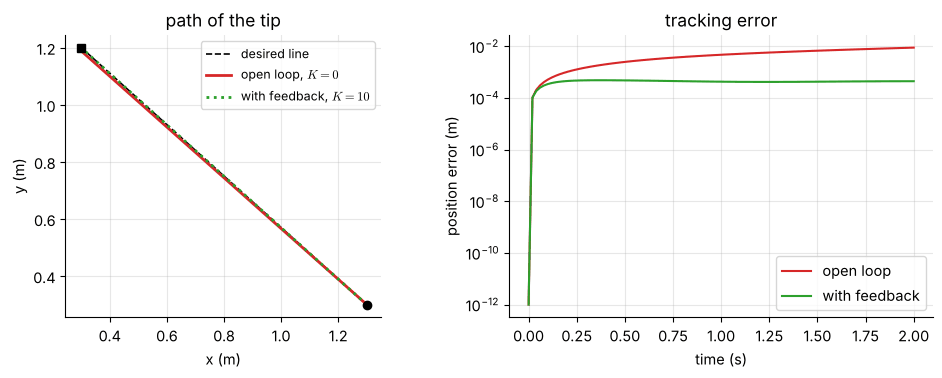

final error: open loop 8.82 mm, with feedback 0.4429 mm


In [8]:
L1, L2 = 1.0, 0.8
def fk2(q): return planar_fk([L1, L2], q)[-1]
def ik2(p, elbow=1):
    c2 = (p @ p - L1 ** 2 - L2 ** 2) / (2 * L1 * L2); s2 = elbow * np.sqrt(1 - c2 ** 2)
    q2 = np.arctan2(s2, c2)
    return np.array([np.arctan2(p[1], p[0]) - np.arctan2(L2 * s2, L1 + L2 * c2), q2])

A, B, T_end, dt = np.array([1.3, 0.3]), np.array([0.3, 1.2]), 2.0, 0.02
times = np.arange(0, T_end + dt / 2, dt)
xd = lambda t: A + (B - A) * t / T_end
xd_dot = (B - A) / T_end

def run(K):
    q = ik2(A); path, err = [fk2(q)], [0.0]
    for t in times[:-1]:
        J = jc.planar_jacobian([L1, L2], q)
        qdot = np.linalg.solve(J, xd_dot + K * (xd(t) - fk2(q)))
        q = q + dt * qdot
        path.append(fk2(q)); err.append(np.linalg.norm(xd(t + dt) - fk2(q)))
    return np.array(path), np.array(err)

p_open, e_open = run(0.0); p_cl, e_cl = run(10.0)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.9))
axs[0].plot([A[0], B[0]], [A[1], B[1]], "k--", lw=1.2, label="desired line")
axs[0].plot(*p_open.T, color="#d62728", lw=2, label="open loop, $K=0$")
axs[0].plot(*p_cl.T, color="#2ca02c", lw=2, ls=":", label="with feedback, $K=10$")
axs[0].plot(*A, "ko"); axs[0].plot(*B, "ks"); axs[0].set_aspect("equal"); axs[0].legend(fontsize=9); axs[0].set_title("path of the tip")
axs[0].set_xlabel("x (m)"); axs[0].set_ylabel("y (m)")
axs[1].semilogy(times, np.maximum(e_open, 1e-12), color="#d62728", label="open loop"); axs[1].semilogy(times, np.maximum(e_cl, 1e-12), color="#2ca02c", label="with feedback")
axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("position error (m)"); axs[1].legend(); axs[1].set_title("tracking error")
plt.tight_layout(); plt.show()
print(f"final error: open loop {e_open[-1]*1000:.2f} mm, with feedback {e_cl[-1]*1000:.4f} mm")

The open-loop error is small but grows steadily — a systematic drift in the direction of curvature of the joint-space path — whereas the feedback law holds the
error to a fraction of a millimetre. **Resolved-rate control with feedback** is the template of all Jacobian-based tracking methods; it fails exactly where
$J^{-1}$ does not exist, which is the subject of Notebooks 5.4 and 5.6.

## 7. Real robots: UR5e, Panda and a Dynamixel two-link arm

MuJoCo returns the Jacobian of any site or body point through `mj_jacSite` / `mj_jac`, as the stacked matrix $[J_p;\ J_r]$ with both parts **expressed in the world frame**
(see `docs/MUJOCO.md`). Our matrices are expressed in the base frame of the arm, so a faithful comparison needs the constant rotation between the world and the base:
${}^{W}J=\operatorname{diag}({}^{W}_{0}R,\ {}^{W}_{0}R)\,{}^{0}J$. For the UR5e, MuJoCo's `base` body is turned $180^\circ$ about $\hat Z$.

**UR5e.** With the D-H table of Notebook 5.1 (`rgkit.jacobian.UR5E_DH`, tool at the flange site), we compare our six columns with `mj_jacSite` at random configurations.

**Panda.** The seven-joint Franka Emika Panda follows Franka's published modified D-H table (`PANDA_DH`), which coincides with the frames in the MuJoCo model. The model has no site at the grasp point, so we choose the *tool centre point*
$0.1034$ m beyond the origin of the `hand` body and ask MuJoCo for the Jacobian of that body-fixed point with `mj_jac`. The result is a $6\times7$ matrix: more columns than rows.

**Dynamixel 2R.** A small educational two-link arm (link lengths $0.18$ m) that moves in the vertical $x$–$z$ plane with its joint axes along $-\hat y$. Measuring the angles from the downward vertical, its tip is at
$(L_1\sin q_1+L_2\sin(q_1+q_2),\ -L_1\cos q_1-L_2\cos(q_1+q_2))$ relative to the shoulder, which is the planar two-link formula after the substitution $(x',y')=(-z,\,x)$.

In [9]:
from rgkit import robots, mujoco_utils as mju
import mujoco

rng = np.random.default_rng(5)

# ---------------- UR5e ----------------
m_ur, d_ur = robots.load_robot("ur5e", scene="bare")
R_wb = jc.UR5E_BASE_IN_WORLD[:3, :3]
err = 0.0
for _ in range(20):
    q = rng.uniform(-np.pi, np.pi, 6)
    d_ur.qpos[:] = q; mujoco.mj_forward(m_ur, d_ur)
    J_mine = jc.jacobian_in_frame(jc.jacobian_geometric(jc.UR5E_DH, q, tool=jc.UR5E_TOOL), R_wb)
    J_mj = jc.mujoco_jacobian(m_ur, d_ur, site="attachment_site")
    err = max(err, np.abs(J_mine - J_mj).max())
print(f"UR5e   : 20 random configurations, max |J_mine - J_MuJoCo| = {err:.1e}   (shapes {J_mine.shape})")

# ---------------- Panda ----------------
m_pa, d_pa = robots.load_robot("panda", scene="bare")
err = 0.0
for _ in range(20):
    q7 = rng.uniform(-2.0, 2.0, 7)
    d_pa.qpos[:] = 0; d_pa.qpos[:7] = q7; mujoco.mj_forward(m_pa, d_pa)
    hand = make_T(d_pa.body("hand").xmat.reshape(3, 3), d_pa.body("hand").xpos)
    tcp = (hand @ transl(0, 0, 0.1034))[:3, 3]
    J_mine = jc.jacobian_geometric(jc.PANDA_DH, q7, tool=jc.PANDA_TOOL)
    J_mj = jc.mujoco_jacobian(m_pa, d_pa, body="hand", point=tcp)[:, :7]
    err = max(err, np.abs(J_mine - J_mj).max())
print(f"Panda  : 20 random configurations, max |J_mine - J_MuJoCo| = {err:.1e}   (shapes {J_mine.shape})")

# ---------------- Dynamixel 2R ----------------
m_2r, d_2r = robots.load_robot("2r", scene="bare")
Lr = 0.18
err = 0.0
for _ in range(20):
    q = rng.uniform(-1.2, 1.2, 2)
    d_2r.qpos[:] = q; mujoco.mj_forward(m_2r, d_2r)
    Jp = jc.planar_jacobian([Lr, Lr], q)                                  # rows: x' = -z, y' = x
    J_world_xz = np.array([Jp[1], -Jp[0]])                              # back to the world rows (x, z)
    J_mj = jc.mujoco_jacobian(m_2r, d_2r, site="end")
    err = max(err, np.abs(J_world_xz - J_mj[[0, 2]]).max(), np.abs(J_mj[4] + 1).max(), np.abs(J_mj[[1, 3, 5]]).max())
print(f"2R     : 20 random configurations, max |J_mine - J_MuJoCo| = {err:.1e}   (rows x, z; angular velocity = -q1dot - q2dot about y)")

UR5e   : 20 random configurations, max |J_mine - J_MuJoCo| = 1.3e-15   (shapes (6, 6))


Panda  : 20 random configurations, max |J_mine - J_MuJoCo| = 3.4e-15   (shapes (6, 7))


2R     : 20 random configurations, max |J_mine - J_MuJoCo| = 4.4e-16   (rows x, z; angular velocity = -q1dot - q2dot about y)


All three robots agree with the simulator to round-off. The agreement is a check of the *table* as well as of the *Jacobian formula*: a wrong offset or sign in the D-H parameters would
move a joint axis and the columns would differ immediately. The next cell tests the meaning of the Jacobian once more, now as a **first-order approximation** of the
motion: a small joint displacement $\Delta\mathbf q=\varepsilon\mathbf u$ moves the tool by $J\Delta\mathbf q$ up to a second-order remainder, so the discrepancy between the exact displacement (from MuJoCo's forward kinematics) and
$J\Delta\mathbf q$ should shrink like $\varepsilon^2$ — a straight line of slope $2$ on a log–log plot.

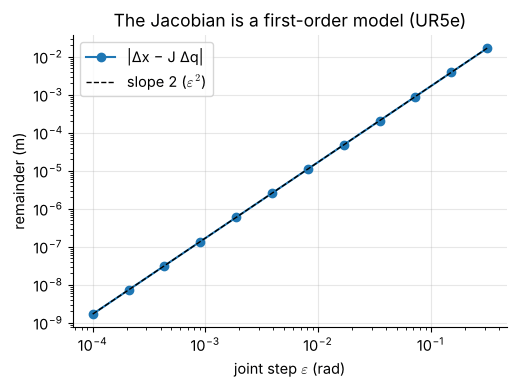

fitted slope = 2.00


In [10]:
q0 = rng.uniform(-2, 2, 6); u = rng.normal(size=6); u /= np.linalg.norm(u)
d_ur.qpos[:] = q0; mujoco.mj_forward(m_ur, d_ur)
p0 = d_ur.site("attachment_site").xpos.copy()
J0 = jc.mujoco_jacobian(m_ur, d_ur, site="attachment_site")[:3]
eps = np.logspace(-4, -0.5, 12); errs = []
for e in eps:
    d_ur.qpos[:] = q0 + e * u; mujoco.mj_forward(m_ur, d_ur)
    errs.append(np.linalg.norm(d_ur.site("attachment_site").xpos - p0 - J0 @ (e * u)))
slope = np.polyfit(np.log(eps), np.log(errs), 1)[0]
plt.figure(figsize=(5.6, 3.8)); plt.loglog(eps, errs, "o-", color="#1f77b4", label="|Δx − J Δq|")
plt.loglog(eps, errs[0] * (eps / eps[0]) ** 2, "k--", lw=1, label=r"slope 2 ($\varepsilon^2$)")
plt.xlabel(r"joint step $\varepsilon$ (rad)"); plt.ylabel("remainder (m)"); plt.legend(); plt.title("The Jacobian is a first-order model (UR5e)"); plt.show()
print(f"fitted slope = {slope:.2f}")

## 8. Worked examples

**Example 5.2.1 — a two-link Jacobian.** For $L_1=0.6$ m, $L_2=0.4$ m, $\theta_1=45^\circ$, $\theta_2=90^\circ$ find $J$ and $\det J$.

*Solution.* $s_1=c_1=0.7071$; $s_{12}=\sin135^\circ=0.7071$, $c_{12}=-0.7071$. Then
$J=\begin{bmatrix}-0.6(0.7071)-0.4(0.7071) & -0.4(0.7071)\\ 0.6(0.7071)-0.4(0.7071) & -0.4(0.7071)\end{bmatrix}=\begin{bmatrix}-0.7071&-0.2828\\ 0.1414&-0.2828\end{bmatrix}$ and
$\det J=0.2000+0.0400=0.2400=L_1L_2\sin\theta_2$.

**Example 5.2.2 — resolved rates.** With the arm of Example 5.2.1, which joint rates give a tip velocity $\dot{\mathbf x}=(0.10,\,-0.05)$ m/s?

*Solution.* $\dot{\mathbf q}=J^{-1}\dot{\mathbf x}$ with $J^{-1}=\frac{1}{0.24}\begin{bmatrix}-0.2828&0.2828\\-0.1414&-0.7071\end{bmatrix}$, giving
$\dot{\mathbf q}=(-0.1768,\ 0.0884)$ rad/s. Substituting back, $J\dot{\mathbf q}=(0.10,-0.05)$.

**Example 5.2.3 — a three-link Jacobian by columns.** For $L=(1.0,0.8,0.5)$ m and $\mathbf q=(30^\circ,-20^\circ,50^\circ)$ build the planar $3\times3$ Jacobian from the column rule and find the tip velocity for $\dot{\mathbf q}=(0.4,-0.2,0.6)$ rad/s.

*Solution.* Column $i$ is $(\hat z\times(\mathbf p_{tip}-\mathbf p_i);\ 1)=(-(y_{tip}-y_i),\ x_{tip}-x_i;\ 1)$. The numbers (joint positions, tip, columns) are printed by the code and agree with the sympy matrix of Section 2; the
tip velocity is $(-0.5742,\ 0.7040)$ m/s with $\dot\phi=0.8$ rad/s, as already found by propagation in Notebook 5.1.

**Example 5.2.4 — the spherical arm.** At $\mathbf q=(35^\circ,25^\circ,0.7\ \mathrm m)$ and $h=0.4$ m find the tool velocity for $\dot{\mathbf q}=(0.5,\,-0.2,\,0.1)$ (rad/s, rad/s, m/s).

*Solution.* $\mathbf v=J_v\dot{\mathbf q}$ with the matrix of Section 5; the radial part $\dot q_3=0.1$ m/s is along the arm, the pan joint gives the tangential velocity $q_3\cos q_2\,\dot q_1=0.3172$ m/s, and the elevation joint moves the tool perpendicular to the arm in the vertical plane at
$q_3\dot q_2=-0.14$ m/s. The code evaluates the full vector and checks it against differentiating the position along the motion.

**Example 5.2.5 — the SCARA.** For the SCARA of Section 5 find the tool velocity for $\dot{\mathbf q}=(0.4,-0.3,0.05,0.2)$.

*Solution.* With $\mathbf q=(30^\circ,60^\circ,0.15,20^\circ)$ the first two columns are $(-0.65,0.433,0)$ and $(-0.40,0,0)$; the third is $(0,0,-1)$ and the fourth contributes only angular velocity. Hence
$\mathbf v=(-0.65(0.4)-0.40(-0.3),\ 0.433(0.4),\ -0.05)=(-0.140,\ 0.1732,\ -0.05)$ m/s, and the angular velocity is $\omega_z=\dot q_1+\dot q_2-\dot q_4=0.4-0.3-0.2=-0.1$ rad/s.

In [11]:
# Example 5.2.1 and 5.2.2
L1, L2 = 0.6, 0.4; q = np.array([deg(45), deg(90)])
J = jc.planar_jacobian([L1, L2], q)
print("5.2.1  J =\n", J, "\n       det J =", np.linalg.det(J).round(4))
assert np.allclose(J, [[-0.7071, -0.2828], [0.1414, -0.2828]], atol=1e-4) and np.isclose(np.linalg.det(J), 0.24)
xd = np.array([0.10, -0.05]); qd = np.linalg.solve(J, xd)
print("5.2.2  qdot =", qd.round(4), " J qdot =", (J @ qd).round(4))
assert np.allclose(qd, [-0.1768, 0.0884], atol=1e-4)

# Example 5.2.3
Lr = [1.0, 0.8, 0.5]; q3 = np.array([deg(30), deg(-20), deg(50)])
pts = planar_fk(Lr, q3)                                          # joint positions and the tip
tip = pts[-1]
cols = np.array([[-(tip[1] - pts[i][1]), tip[0] - pts[i][0], 1.0] for i in range(3)]).T
print("5.2.3  joint positions:\n", pts.round(4), "\n       J (rows vx, vy, wz) =\n", cols.round(4))
assert np.allclose(cols, jc.planar_jacobian(Lr, q3, orientation=True))
assert np.allclose(cols, np.array(J_sym.subs(dict(zip(L, Lr)) | dict(zip(th, q3))), dtype=float), atol=1e-9)
qd3 = np.array([0.4, -0.2, 0.6]); print("       tip velocity and phidot:", (cols @ qd3).round(4))
assert np.allclose(cols @ qd3, [-0.5742, 0.7040, 0.8], atol=1e-4)

# Example 5.2.4
qd = np.array([0.5, -0.2, 0.1])
v = jc.jacobian_geometric(rrp, qv)[:3] @ qd
pos = lambda t: np.array(p_sym.subs({q1s: qv[0] + qd[0] * t, q2s: qv[1] + qd[1] * t, q3s: qv[2] + qd[2] * t}), dtype=float).ravel()
v_num = (pos(1e-6) - pos(-1e-6)) / 2e-6
print("5.2.4  v =", v.round(4), " numerical derivative:", v_num.round(4))
assert np.allclose(v, v_num, atol=1e-6)
assert np.isclose(qv[2] * np.cos(qv[1]) * qd[0], 0.3172, atol=1e-4) and np.isclose(qv[2] * qd[1], -0.14)

# Example 5.2.5
qd_s = np.array([0.4, -0.3, 0.05, 0.2]); tw = Js @ qd_s
print("5.2.5  twist =", tw.round(4)); assert np.allclose(tw, [-0.140, 0.1732, -0.05, 0, 0, -0.1], atol=1e-4)
print("all worked examples verified")

5.2.1  J =
 [[-0.7071 -0.2828]
 [ 0.1414 -0.2828]] 
       det J = 0.24
5.2.2  qdot = [-0.1768  0.0884]  J qdot = [ 0.1  -0.05]
5.2.3  joint positions:
 [[0.     0.    ]
 [0.866  0.5   ]
 [1.6539 0.6389]
 [1.9039 1.0719]] 
       J (rows vx, vy, wz) =
 [[-1.0719 -0.5719 -0.433 ]
 [ 1.9039  1.0378  0.25  ]
 [ 1.      1.      1.    ]]
       tip velocity and phidot: [-0.5742  0.704   0.8   ]
5.2.4  v = [-0.0592  0.3458 -0.0846]  numerical derivative: [-0.0592  0.3458 -0.0846]
5.2.5  twist = [-0.14    0.1732 -0.05    0.     -0.     -0.1   ]
all worked examples verified


## 9. Summary

| Result | Formula |
|:--|:--|
| Definition | $\dot{\mathbf x}=J(\mathbf q)\dot{\mathbf q}$, $J=\partial f/\partial\mathbf q$ for position rows; $6\times n$ geometric Jacobian for $[\mathbf v;\boldsymbol\omega]$ |
| Revolute column | $\big[\hat{\mathbf z}_i\times(\mathbf p_n-\mathbf p_i);\ \hat{\mathbf z}_i\big]$ |
| Prismatic column | $[\hat{\mathbf z}_i;\ \mathbf 0]$ |
| Propagation route | $\dot{\mathbf q}=\mathbf e_j$ in the outward iteration $\Rightarrow$ column $j$ of ${}^{n}J$ |
| Planar 2R | $J=\begin{bmatrix}-L_1s_1-L_2s_{12}&-L_2s_{12}\\L_1c_1+L_2c_{12}&L_2c_{12}\end{bmatrix}$, $\det J=L_1L_2\sin\theta_2$ |
| Resolved rate | $\dot{\mathbf q}=J^{-1}(\dot{\mathbf x}_d+K(\mathbf x_d-\mathbf x))$ |
| MuJoCo | `mj_jacSite` / `mj_jac` return $[J_p;J_r]$ in the **world** frame |

### Common mistakes

* Using the *standard*-convention rule (axis $=\hat z_{i-1}$) with a *modified* D-H table, or vice versa.
* Using the origin of the wrong frame for $\mathbf p_n$: the Jacobian refers to a **point**, and moving the tool point changes the linear rows (Notebook 5.3).
* Comparing a base-frame Jacobian with MuJoCo's world-frame Jacobian without the constant rotation between the two.
* Expecting an orientation row to be the derivative of Euler angles: the bottom block is $\boldsymbol\omega$, not $\dot\alpha,\dot\beta,\dot\gamma$.
* Integrating $\dot{\mathbf q}=J^{-1}\dot{\mathbf x}_d$ with no feedback over long paths.

## Exercises

**5.2.1** Derive the Jacobian of the planar two-link arm for the tip position by differentiation, and show that $\det J=L_1L_2\sin\theta_2$.

<details><summary>Answer</summary>

See Section 2. $\det J=(-L_1s_1-L_2s_{12})L_2c_{12}-(-L_2s_{12})(L_1c_1+L_2c_{12})=L_1L_2(s_{12}c_1-c_{12}s_1)=L_1L_2\sin\theta_2$, because
the $L_2^2$ terms cancel and $\sin(\theta_{12}-\theta_1)=\sin\theta_2$.
</details>

**5.2.2** A planar two-link arm has $L_1=0.5$ m, $L_2=0.3$ m. At $\theta_1=20^\circ$, $\theta_2=70^\circ$ the joints move at $\dot\theta=(0.5,\,1.0)$ rad/s. Find the tip velocity and its speed.

<details><summary>Answer</summary>

$J=\begin{bmatrix}-0.4710&-0.3000\\ 0.4698&\ 0.0000\end{bmatrix}$ (since $s_{12}=1$, $c_{12}=0$), so $\mathbf v=J\dot{\boldsymbol\theta}=(-0.5355,\ 0.2349)$ m/s and the speed is $0.5848$ m/s (verified in the cell below).
</details>

**5.2.3** For the three-link arm of Example 5.2.3 find $\dot{\mathbf q}$ that moves the tip along $+\hat x$ at $0.2$ m/s while keeping the tool orientation constant ($\dot\phi=0$).

<details><summary>Answer</summary>

Solve $J\dot{\mathbf q}=(0.2,\,0,\,0)^{\mathsf T}$ with the $3\times3$ planar Jacobian: $\dot{\mathbf q}=(-0.5759,\ 1.2089,\ -0.6330)$ rad/s. The arm is not singular ($\det J=L_1L_2\sin\theta_2=-0.2736$), but $\theta_2=-20^\circ$ is close enough to the stretched configuration that a tip speed of only $0.2$ m/s already needs joint rates above 1 rad/s — a preview of Notebook 5.4 (numbers verified below).
</details>

**5.2.4** Write down, without computing any trigonometry, the Jacobian columns of a *cylindrical* RPP arm (vertical revolute $q_1$, vertical prismatic $q_2$, horizontal radial prismatic $q_3$) at a configuration where the radial direction is $\hat x$ and the tool is at radius $r$.

<details><summary>Answer</summary>

The revolute column is $[\hat z\times(r\hat x);\ \hat z]=[(0,r,0);\,(0,0,1)]$; the vertical prismatic column is $[(0,0,1);\,\mathbf 0]$; the radial prismatic column is $[(1,0,0);\,\mathbf 0]$.
</details>

**5.2.5** Show with the column rule that the Jacobian of the SCARA of Section 5 has rank 4 for every $\mathbf q$ in which the arm is not folded or stretched, and give the linear velocity direction that the first two joints cannot produce.

<details><summary>Answer</summary>

Columns 3 and 4 are $(0,0,-1,0,0,0)^{\mathsf T}$ and $(0,0,0,0,0,-1)^{\mathsf T}$. Columns 1 and 2 have the form $(\mathbf a_i,\ 0,\ 0,\ 0,\ 1)$ with horizontal linear parts $\mathbf a_1,\mathbf a_2$; the determinant of the $2\times2$ matrix $[\mathbf a_1\ \mathbf a_2]$ is $L_1L_2\sin\theta_2$. For $\sin\theta_2\neq0$ the four columns are therefore independent (rank 4); at $\theta_2=0$ or $\pi$ the rank falls to 3.
Whatever the configuration, the velocities $\omega_x,\omega_y$ (tilting the tool) are impossible, because every column has zero entries in rows 4 and 5.
</details>

**5.2.6** (*Programming*) Write a function that returns the numerical Jacobian of any `fk(q)` by central differences with step $10^{-6}$ and check it against `jacobian_geometric` for the Panda at a random configuration.

<details><summary>Answer</summary>

Use `jc.jacobian_numeric(lambda x: fk_tool(jc.PANDA_DH, x, tool=jc.PANDA_TOOL), q)` or write the loop yourself (perturb one joint at a time, difference positions; for the angular part take the rotation vector of $R(q+h)R(q-h)^{\mathsf T}$ divided by $2h$). The maximum difference printed in the cell below is below $10^{-8}$.
</details>

**5.2.7** (*MuJoCo*) Using the Dynamixel 2R model, find a configuration at which MuJoCo's Jacobian has rank one, and state the tip direction in which the arm cannot move.

<details><summary>Answer</summary>

At $q_2=0$ (arm stretched along the vertical) $\det J=L_1L_2\sin q_2=0$; the tip cannot move *along the arm*, i.e. vertically, only horizontally. The cell below shows $J_z=0$ at $q=(0,0)$ and rank $1$ in the $(x,z)$ rows.
</details>

In [12]:
# --- verification of exercise answers ---------------------------------------------------------------
# 5.2.2
J = jc.planar_jacobian([0.5, 0.3], [deg(20), deg(70)]); v = J @ [0.5, 1.0]
print("5.2.2  J =\n", J.round(4), "\n       v =", v.round(4), " speed =", np.linalg.norm(v).round(4))
assert np.allclose(J, [[-0.4710, -0.3], [0.4698, 0.0]], atol=1e-4) and np.allclose(v, [-0.5355, 0.2349], atol=1e-4) and abs(np.linalg.norm(v) - 0.5848) < 1e-4

# 5.2.3
J3 = jc.planar_jacobian(Lr, q3, orientation=True)
qd = np.linalg.solve(J3, [0.2, 0, 0])
print("5.2.3  qdot =", qd.round(4), " det J =", np.linalg.det(J3).round(4))
assert np.allclose(qd, [-0.5759, 1.2089, -0.6330], atol=1e-4) and np.isclose(np.linalg.det(J3), -0.2736, atol=1e-4)

# 5.2.4: cylindrical RPP; radial direction = x when q1 = 0 (theta offset 90 degrees)
r, z0 = 0.7, 0.3
cyl_tab = [(0, 0, 0, np.pi / 2, "R"), (0, 0, 0, 0, "P"), (np.pi / 2, 0, 0, 0, "P")]
Jc = jc.jacobian_geometric(cyl_tab, [0.0, z0, r])
expected = np.array([[0, r, 0, 0, 0, 1], [0, 0, 1, 0, 0, 0], [1, 0, 0, 0, 0, 0]], float).T
print("5.2.4  columns of the cylindrical-arm Jacobian:\n", Jc.round(3)); assert np.allclose(Jc, expected)
assert np.allclose(fk_dh(cyl_tab, [0.0, z0, r])[-1][:3, 3], [r, 0, z0])

# 5.2.6
qp = rng.uniform(-2, 2, 7)
Jn = jc.jacobian_numeric(lambda x: fk_tool(jc.PANDA_DH, x, tool=jc.PANDA_TOOL), qp)
print("5.2.6  max |J_numeric - J_geometric| =", np.abs(Jn - jc.jacobian_geometric(jc.PANDA_DH, qp, tool=jc.PANDA_TOOL)).max())
assert np.allclose(Jn, jc.jacobian_geometric(jc.PANDA_DH, qp, tool=jc.PANDA_TOOL), atol=1e-8)

# 5.2.7
d_2r.qpos[:] = [0.0, 0.0]; mujoco.mj_forward(m_2r, d_2r)
J2 = jc.mujoco_jacobian(m_2r, d_2r, site="end")
print("5.2.7  rank of the (x, z) rows at q = (0, 0):", np.linalg.matrix_rank(J2[[0, 2]]), "  J_z row:", J2[2])
assert np.linalg.matrix_rank(J2[[0, 2]]) == 1 and np.allclose(J2[2], 0)

5.2.2  J =
 [[-0.471  -0.3   ]
 [ 0.4698  0.    ]] 
       v = [-0.5355  0.2349]  speed = 0.5848
5.2.3  qdot = [-0.5759  1.2089 -0.633 ]  det J = -0.2736
5.2.4  columns of the cylindrical-arm Jacobian:
 [[ 0.   0.   1. ]
 [ 0.7  0.  -0. ]
 [-0.   1.   0. ]
 [ 0.   0.   0. ]
 [ 0.   0.   0. ]
 [ 1.   0.   0. ]]
5.2.6  max |J_numeric - J_geometric| = 1.190946230522627e-10
5.2.7  rank of the (x, z) rows at q = (0, 0): 1   J_z row: [0. 0.]


## Further reading and lectures

* Craig, Ch. 5, §5.6 (Jacobians); Lynch & Park §5.1; Siciliano et al. Ch. 3; Corke *RVC* Ch. 8.
* Video: [ThatsEngineering — Jacobian matrix and singularities (part 1)](https://www.youtube.com/watch?v=h2YM0CDzDl4); [ThatsEngineering — Jacobian by partial differentiation (part 2)](https://www.youtube.com/watch?v=YS3kt_eqOPY); [Modern Robotics — 5.1.1 Space Jacobian](https://www.youtube.com/watch?v=KbI8HN3imtQ); [Modern Robotics — 5.1.2 Body Jacobian](https://www.youtube.com/watch?v=69HeL2XvL9Y); [Modern Robotics — Ch. 5 Velocity kinematics and statics](https://www.youtube.com/watch?v=6tj8QLF69Ok).
* MuJoCo: [mujoco.readthedocs.io](https://mujoco.readthedocs.io/) (`mj_jac`, `mj_jacSite`); `docs/MUJOCO.md` of this repository (Section 4).

---

[← 5.1 Velocity of Rigid Bodies and Velocity Propagation](5.1-velocity-of-rigid-bodies-and-propagation.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md) &nbsp;·&nbsp; [5.3 Jacobians in Other Frames and the Analytical Jacobian →](5.3-frames-and-the-analytical-jacobian.ipynb)